# Task 5: Topic Modeling on News Articles (LDA vs NMF)
**Dataset:** BBC News (Kaggle) &nbsp;|&nbsp; **Tools:** Gensim, NLTK/sklearn, pyLDAvis, WordCloud, Scikit-learn

**Pipeline:** Load data -> Preprocess (tokenize, lowercase, stopwords, lemmatize) -> LDA (choose k by coherence) -> Top words per topic -> Visualize (word clouds + pyLDAvis) -> **Bonus:** NMF and LDA vs NMF comparison.

In [2]:
import sys, subprocess, importlib
def ensure(pkg, mod=None):
    try:
        importlib.import_module(mod or pkg)
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg])
ensure("gensim"); ensure("pyLDAvis"); ensure("wordcloud")

import re, time, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import gensim
from gensim import corpora
from gensim.models import LdaMulticore, CoherenceModel
from gensim.parsing.preprocessing import STOPWORDS as GENSIM_STOP
from gensim.utils import simple_preprocess
from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.decomposition import NMF
from wordcloud import WordCloud
import pyLDAvis
import pyLDAvis.gensim_models as gensimvis
warnings.filterwarnings("ignore")
pyLDAvis.enable_notebook()
SEED = 42
np.random.seed(SEED)
print("gensim", gensim.__version__)

gensim 4.4.0


## 1. Load the data

In [3]:
DATA_PATH = "/kaggle/input/datasets/sahilkirpekar/bbcnews-dataset/BBCNews.csv"
df = pd.read_csv(DATA_PATH)
print("Shape:", df.shape)
print("Columns:", list(df.columns))
df.head()

Shape: (2410, 3)
Columns: ['Unnamed: 0', 'descr', 'tags']


,Unnamed: 0,descr,tags
0,0,chelsea sack mutu chelsea have sacked adrian ...,"sports, stamford bridge, football association,..."
1,1,record fails to lift lacklustre meet yelena i...,"sports, madrid, birmingham, france, scotland, ..."
2,2,edu describes tunnel fracas arsenals edu has ...,"sports, derby, brazil, tunnel fracasedu, food,..."
3,3,ogara revels in ireland victory ireland flyha...,"sports, bbc, united kingdom, ireland, brian o'..."
4,4,unclear future for striker baros liverpool fo...,"sports, liverpool, daily sport, millennium sta..."


The notebook auto-detects the text columns (it combines `title` + `description` if they exist; otherwise it uses the column with the longest text), so it works whatever the exact schema is.

In [4]:
cols_lower = {c.lower(): c for c in df.columns}
text_cols = [cols_lower[c] for c in ["title", "description", "text", "content", "headline", "body"] if c in cols_lower]
if not text_cols:
    obj_cols = df.select_dtypes(include="object").columns
    text_cols = [max(obj_cols, key=lambda c: df[c].astype(str).str.len().mean())]
print("Using text columns:", text_cols)

df["text"] = df[text_cols].fillna("").astype(str).agg(" ".join, axis=1).str.strip()
df = df[df["text"].str.len() > 0].drop_duplicates(subset="text").reset_index(drop=True)
print("Documents after cleaning:", len(df))
print("Avg. characters per doc:", int(df["text"].str.len().mean()))
df["text"].sample(3, random_state=SEED).tolist()

Using text columns: ['descr']
Documents after cleaning: 2128
Avg. characters per doc: 2174


['straw backs ending china embargo  uk foreign secretary jack straw has defended plans to end the european unions arms embargo on china despite opposition from the us and japan  mr straw visiting beijing noted arms embargoes applied to china burma and zimbabwe but not to north korea which he said had a terrible rights record the eu imposed its arms ban on china in  after troops opened fire on protestors in tiananmen square mr straw also signed a deal on chinauk tourism it is expected this would increase the number of chinese tourists by  per year providing m in revenue china has in the past said it sees the weapons ban as politically driven and does not want it lifted in order to buy more weapons mr straw speaking at a joint news conference with chinese foreign minister li zhaoxing stressed this point the result of any decision to lift the arms embargo should not be an increase in arms exports from european union member states to china either in quantitative or qualitative terms mr str

## 2. Preprocessing
Tokenization, lowercasing, stopword removal, short-token removal, and lemmatization (if WordNet is available offline).

In [5]:
# Lemmatizer (optional: needs WordNet; Kaggle internet may be off, so we fall back gracefully)
lemmatizer = None
try:
    import nltk
    from nltk.stem import WordNetLemmatizer
    try:
        nltk.data.find("corpora/wordnet")
    except LookupError:
        nltk.download("wordnet", quiet=True)
    lemmatizer = WordNetLemmatizer()
    lemmatizer.lemmatize("tests")  # test that it really works
    print("Lemmatization: ON")
except Exception as e:
    lemmatizer = None
    print("Lemmatization: OFF (WordNet unavailable) ->", type(e).__name__)

STOPWORDS = set(GENSIM_STOP) | set(ENGLISH_STOP_WORDS)
try:
    from nltk.corpus import stopwords
    STOPWORDS |= set(stopwords.words("english"))
except Exception:
    pass
# domain-specific noise words common in news text
STOPWORDS |= {"say","says","said","new","news","bbc","year","years","day","days","week","mr","mrs","ms","us","uk","one","two","also","get","got","make","like","amp"}

def preprocess(text):
    text = re.sub(r"http\S+|www\.\S+", " ", text)
    tokens = simple_preprocess(text, deacc=True, min_len=3, max_len=20)   # tokenize + lowercase
    tokens = [t for t in tokens if t not in STOPWORDS]
    if lemmatizer:
        tokens = [lemmatizer.lemmatize(t) for t in tokens]
    return [t for t in tokens if t not in STOPWORDS and len(t) >= 3]

df["tokens"] = df["text"].map(preprocess)
df = df[df["tokens"].map(len) >= 3].reset_index(drop=True)
texts = df["tokens"].tolist()
print("Docs kept:", len(texts))
print("Original :", df["text"].iloc[0][:200])
print("Tokens   :", texts[0][:20])

Lemmatization: ON
Docs kept: 2128
Original : chelsea sack mutu  chelsea have sacked adrian mutu after he failed a drugs test  the yearold tested positive for a banned substance  which he later denied was cocaine  in october chelsea have decided 
Tokens   : ['chelsea', 'sack', 'mutu', 'chelsea', 'sacked', 'adrian', 'mutu', 'failed', 'drug', 'test', 'yearold', 'tested', 'positive', 'banned', 'substance', 'later', 'denied', 'cocaine', 'october', 'chelsea']


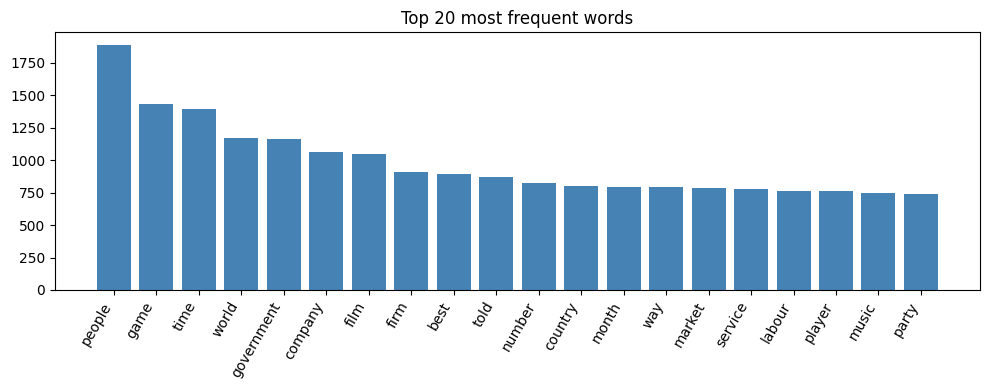

In [6]:
# Most frequent words overall
from collections import Counter
cnt = Counter(w for doc in texts for w in doc)
top = cnt.most_common(20)
plt.figure(figsize=(10,4))
plt.bar([w for w,_ in top], [c for _,c in top], color="steelblue")
plt.xticks(rotation=60, ha="right"); plt.title("Top 20 most frequent words"); plt.tight_layout(); plt.show()

## 3. Dictionary & Bag-of-Words corpus

In [7]:
dictionary = corpora.Dictionary(texts)
print("Vocab before filtering:", len(dictionary))
dictionary.filter_extremes(no_below=5, no_above=0.5, keep_n=20000)
print("Vocab after filtering :", len(dictionary))
corpus = [dictionary.doc2bow(t) for t in texts]

Vocab before filtering: 27439
Vocab after filtering : 7667


## 4. LDA: choosing the number of topics (k) using Coherence (c_v)

k= 3  coherence c_v = 0.3512


k= 4  coherence c_v = 0.5123


k= 5  coherence c_v = 0.5160


k= 6  coherence c_v = 0.5444


k= 7  coherence c_v = 0.5452


k= 8  coherence c_v = 0.5186


k= 9  coherence c_v = 0.5540


k=10  coherence c_v = 0.5574


k=11  coherence c_v = 0.5471
k=12  coherence c_v = 0.5150


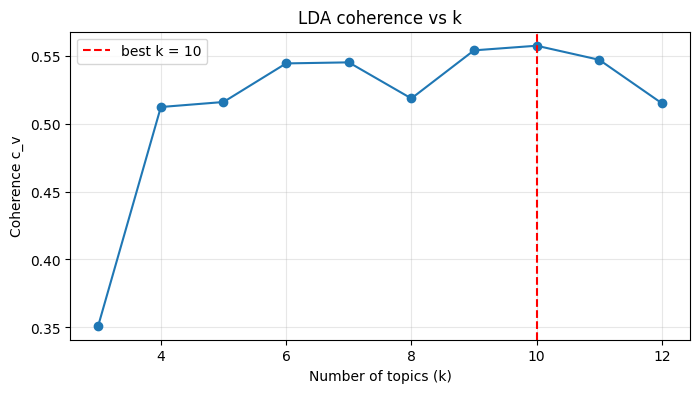

Best k: 10


In [8]:
k_values = list(range(3, 13))
coh_scores = []
for k in k_values:
    m = LdaMulticore(corpus=corpus, id2word=dictionary, num_topics=k, passes=8,
                     workers=2, random_state=SEED, chunksize=2000)
    c = CoherenceModel(model=m, texts=texts, dictionary=dictionary, coherence="c_v").get_coherence()
    coh_scores.append(c)
    print(f"k={k:2d}  coherence c_v = {c:.4f}")

best_k = k_values[int(np.argmax(coh_scores))]
plt.figure(figsize=(8,4))
plt.plot(k_values, coh_scores, marker="o")
plt.axvline(best_k, color="r", ls="--", label=f"best k = {best_k}")
plt.xlabel("Number of topics (k)"); plt.ylabel("Coherence c_v"); plt.title("LDA coherence vs k"); plt.legend(); plt.grid(alpha=.3); plt.show()
print("Best k:", best_k)

## 5. Train the final LDA model & show top words per topic

In [9]:
NUM_TOPICS = best_k       # you can override manually, e.g. NUM_TOPICS = 5
t0 = time.time()
lda = LdaMulticore(corpus=corpus, id2word=dictionary, num_topics=NUM_TOPICS, passes=15,
                   iterations=100, workers=2, random_state=SEED, chunksize=2000, per_word_topics=True)
lda_time = time.time() - t0

print(f"LDA trained in {lda_time:.1f}s with {NUM_TOPICS} topics\n")
for tid in range(NUM_TOPICS):
    words = [f"{w} ({p:.3f})" for w, p in lda.show_topic(tid, topn=10)]
    print(f"Topic {tid}: " + ", ".join(words))

LDA trained in 23.2s with 10 topics

Topic 0: game (0.013), people (0.008), software (0.008), time (0.006), apple (0.005), program (0.005), way (0.005), user (0.005), firm (0.005), virus (0.005)
Topic 1: labour (0.014), party (0.014), election (0.012), people (0.011), tory (0.010), government (0.008), howard (0.007), blair (0.006), minister (0.006), plan (0.006)
Topic 2: best (0.015), award (0.009), sale (0.008), film (0.008), people (0.008), million (0.006), time (0.006), british (0.006), director (0.005), european (0.005)
Topic 3: game (0.011), england (0.009), player (0.008), win (0.007), team (0.006), time (0.006), club (0.006), ireland (0.006), cup (0.006), wale (0.005)
Topic 4: game (0.016), technology (0.008), open (0.008), player (0.008), set (0.007), gadget (0.006), world (0.005), search (0.005), device (0.005), people (0.005)
Topic 5: firm (0.013), company (0.013), phone (0.012), mobile (0.012), service (0.011), people (0.010), net (0.007), network (0.007), user (0.006), shar

### Word clouds for each LDA topic

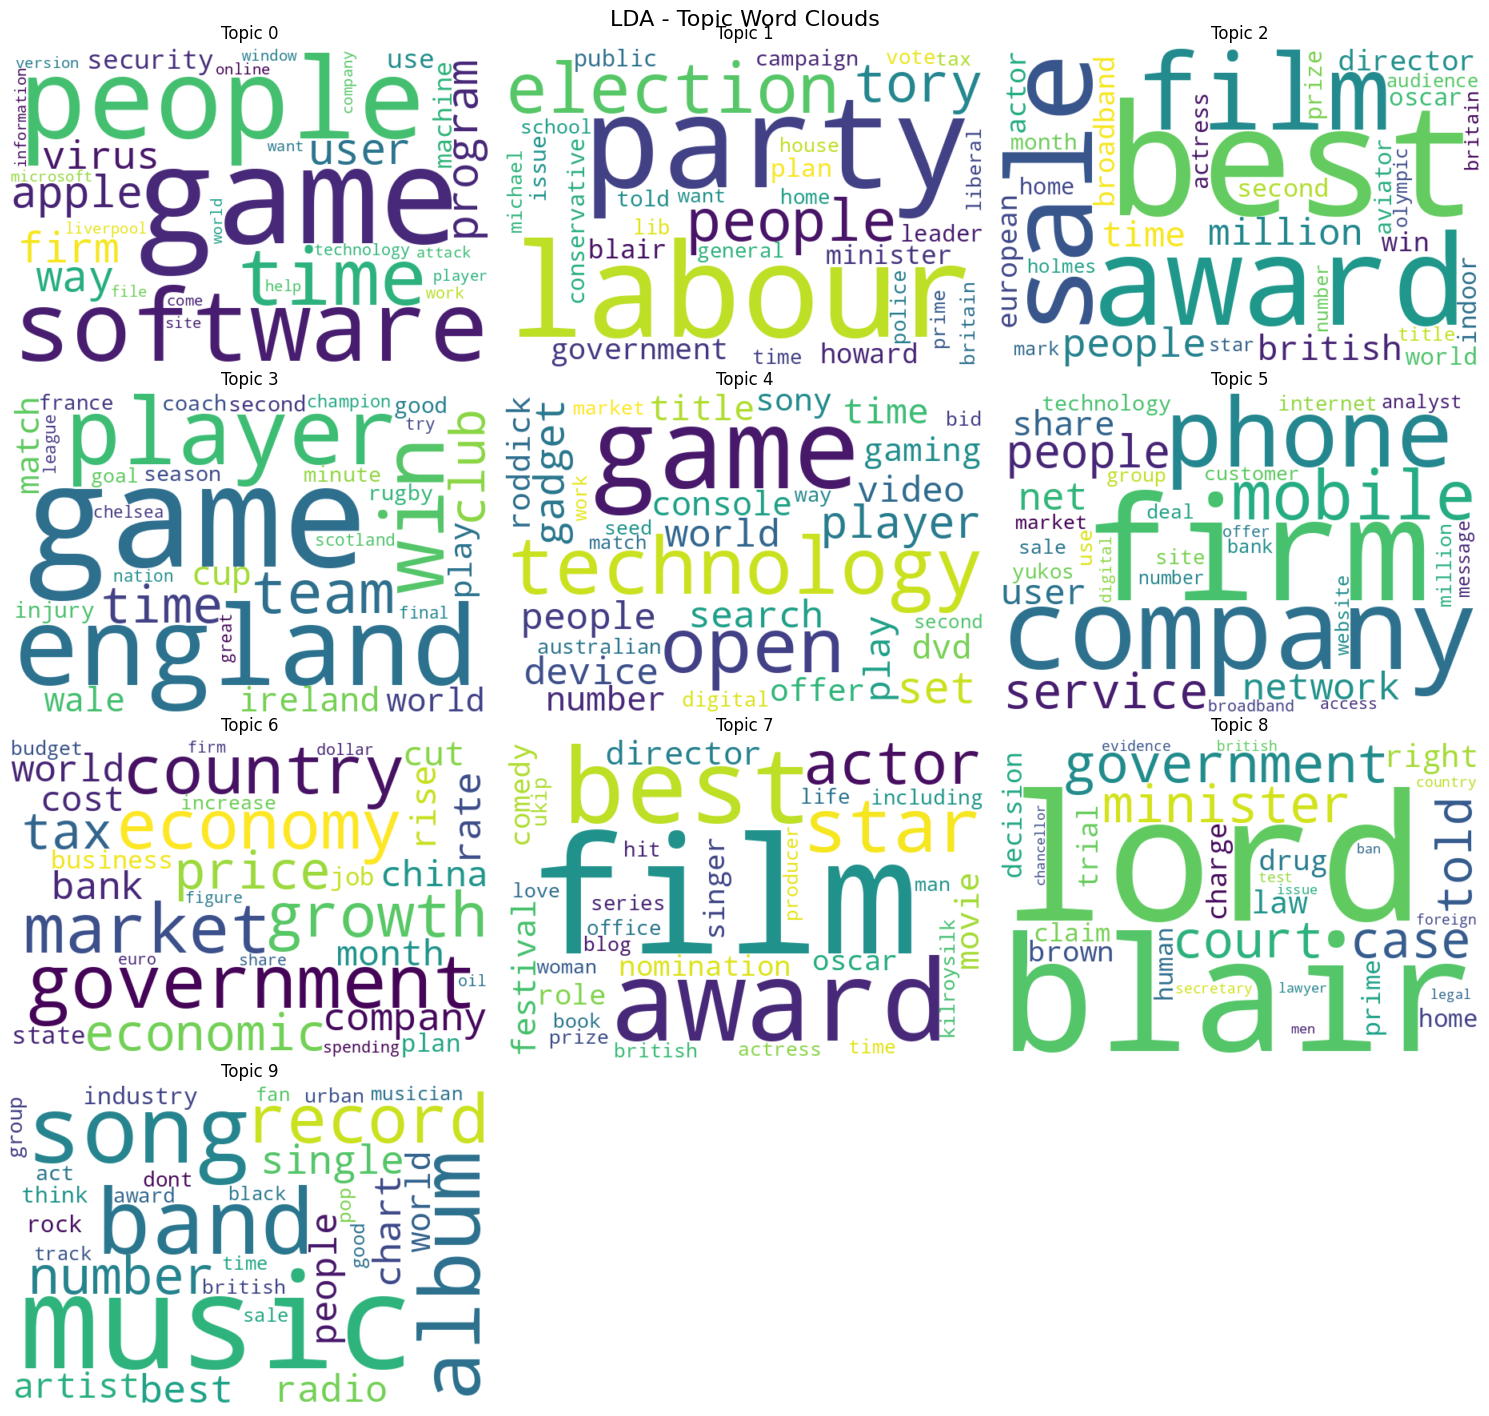

In [10]:
def plot_wordclouds(get_topic_words, n_topics, title):
    cols = 3
    rows = int(np.ceil(n_topics / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(5*cols, 3.6*rows))
    axes = np.array(axes).reshape(-1)
    for i in range(n_topics):
        freqs = dict(get_topic_words(i))
        wc = WordCloud(width=600, height=400, background_color="white", colormap="viridis").generate_from_frequencies(freqs)
        axes[i].imshow(wc, interpolation="bilinear"); axes[i].axis("off"); axes[i].set_title(f"Topic {i}")
    for j in range(n_topics, len(axes)): axes[j].axis("off")
    fig.suptitle(title, fontsize=16); plt.tight_layout(); plt.show()

plot_wordclouds(lambda i: lda.show_topic(i, topn=30), NUM_TOPICS, "LDA - Topic Word Clouds")

## 6. Interactive visualization with pyLDAvis

In [11]:
vis = gensimvis.prepare(lda, corpus, dictionary, sort_topics=False)
pyLDAvis.save_html(vis, "lda_visualization.html")   # also saved to /kaggle/working
vis

PreparedData(topic_coordinates=              x         y  topics  cluster       Freq
topic                                                
0      0.037468 -0.118399       1        1   8.877836
1      0.118607  0.112497       2        1  13.691068
2     -0.142013 -0.018865       3        1   4.878228
3     -0.092930  0.101794       4        1  14.244711
4     -0.039034 -0.124710       5        1   7.678115
5      0.102500 -0.153903       6        1  10.888702
6      0.135598 -0.016285       7        1  18.045648
7     -0.160799  0.052917       8        1   8.200198
8      0.140575  0.149614       9        1   8.431571
9     -0.099972  0.015341      10        1   5.063923, topic_info=         Term         Freq        Total Category  logprob  loglift
575      film   997.000000   997.000000  Default  30.0000  30.0000
5023    music   715.000000   715.000000  Default  29.0000  29.0000
63       game  1401.000000  1401.000000  Default  28.0000  28.0000
3865   labour   779.000000   779.000000  Default  27.0000  27.0000
153      best   842.000000   842.000000  Default  26.0000  26.0000
...       ...          ...          ...      ...      ...      ...
583     group    64.359186   597.096395  Topic10  -5.6008   0.7554
161   british    60.436963   501.992035  Topic10  -5.6637   0.8660
643      sale    54.117274   674.078174  Topic10  -5.7741   0.4608
289      time    53.897254  1366.388633  Topic10  -5.7782  -0.2498
200      good    51.512827   661.423762  Topic10  -5.8235   0.4305

[758 rows x 6 columns], token_table=      Topic      Freq        Term
term                             
137       3  0.927055         aaa
4172      1  0.202383      access
4172      2  0.116933      access
4172      3  0.031482      access
4172      5  0.035979      access
...     ...       ...         ...
7472      9  0.924341  yushchenko
1146      4  0.922057     zealand
1146      7  0.040530     zealand
1146      9  0.010132     zealand
1146     10  0.020265     zealand

[2661 rows x 3 columns], R=30, lambda_step=0.01, plot_opts={'xlab': 'PC1', 'ylab': 'PC2'}, topic_order=[1, 2, 3, 4, 5, 6, 7, 8, 9, 10])

## 7. Dominant topic per document

lda_topic
0    144
1    264
2     83
3    369
4    165
5    223
6    415
7    217
8    155
9     93
Name: count, dtype: int64


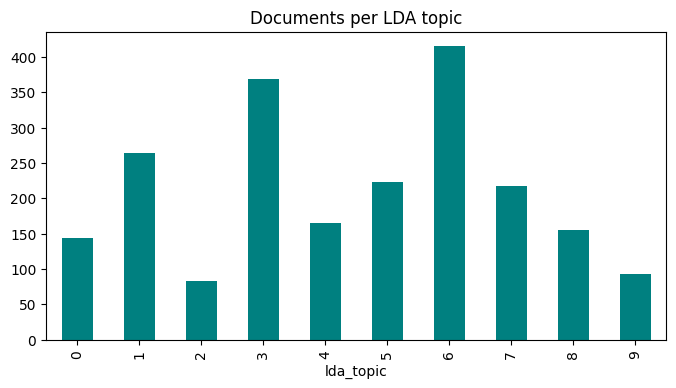

,text,lda_topic,lda_prob
282,straw backs ending china embargo uk foreign s...,8,0.677763
2000,beijingers fume over parking fees choking tra...,6,0.430366
1706,dirty dens demise seen by m more than millio...,2,0.831479
988,uk debut for kevin spacey movie hollywood sta...,7,0.992496
2019,us to probe airline travel chaos the us gover...,6,0.995828
297,blair said he would stand down tony blair pro...,8,0.930754
1738,original exorcist to be screened the original...,7,0.991887
651,tv future in the hands of viewers with home t...,4,0.518149


In [12]:
def dominant_topic(bow):
    topics = lda.get_document_topics(bow, minimum_probability=0)
    return max(topics, key=lambda x: x[1])

dom = [dominant_topic(b) for b in corpus]
df["lda_topic"] = [t for t, _ in dom]
df["lda_prob"] = [p for _, p in dom]

print(df["lda_topic"].value_counts().sort_index())
df["lda_topic"].value_counts().sort_index().plot(kind="bar", figsize=(8,4), color="teal", title="Documents per LDA topic")
plt.show()

df[["text", "lda_topic", "lda_prob"]].sample(8, random_state=SEED)

## 8. Bonus: NMF (TF-IDF + Non-negative Matrix Factorization)

In [13]:
docs_clean = [" ".join(t) for t in texts]
vocab = list(dictionary.token2id.keys())            # same vocabulary as LDA for a fair comparison
tfidf = TfidfVectorizer(vocabulary=vocab, max_df=0.5)
X = tfidf.fit_transform(docs_clean)
feature_names = np.array(tfidf.get_feature_names_out())

t0 = time.time()
nmf = NMF(n_components=NUM_TOPICS, init="nndsvd", random_state=SEED, max_iter=400)
W = nmf.fit_transform(X)
nmf_time = time.time() - t0
print(f"NMF trained in {nmf_time:.2f}s | reconstruction error: {nmf.reconstruction_err_:.4f}\n")

def nmf_topic_words(i, topn=10):
    idx = nmf.components_[i].argsort()[::-1][:topn]
    return [(feature_names[j], nmf.components_[i][j]) for j in idx]

for tid in range(NUM_TOPICS):
    print(f"Topic {tid}: " + ", ".join(w for w, _ in nmf_topic_words(tid)))

df["nmf_topic"] = W.argmax(axis=1)

NMF trained in 1.15s | reconstruction error: 43.9424

Topic 0: club, chelsea, liverpool, arsenal, league, united, player, goal, cup, mourinho
Topic 1: labour, election, party, blair, tory, brown, tax, howard, government, minister
Topic 2: growth, economy, rate, economic, price, bank, market, dollar, rise, figure
Topic 3: film, award, best, oscar, actor, festival, actress, director, star, nomination
Topic 4: mobile, phone, people, technology, service, user, broadband, network, net, digital
Topic 5: yukos, company, firm, oil, share, court, russian, gazprom, deal, russia
Topic 6: music, band, album, chart, song, single, rock, award, number, singer
Topic 7: game, console, gaming, video, nintendo, gamers, xbox, title, sony, sale
Topic 8: england, wale, ireland, rugby, robinson, france, nation, coach, scotland, player
Topic 9: world, champion, olympic, open, race, win, final, seed, second, indoor


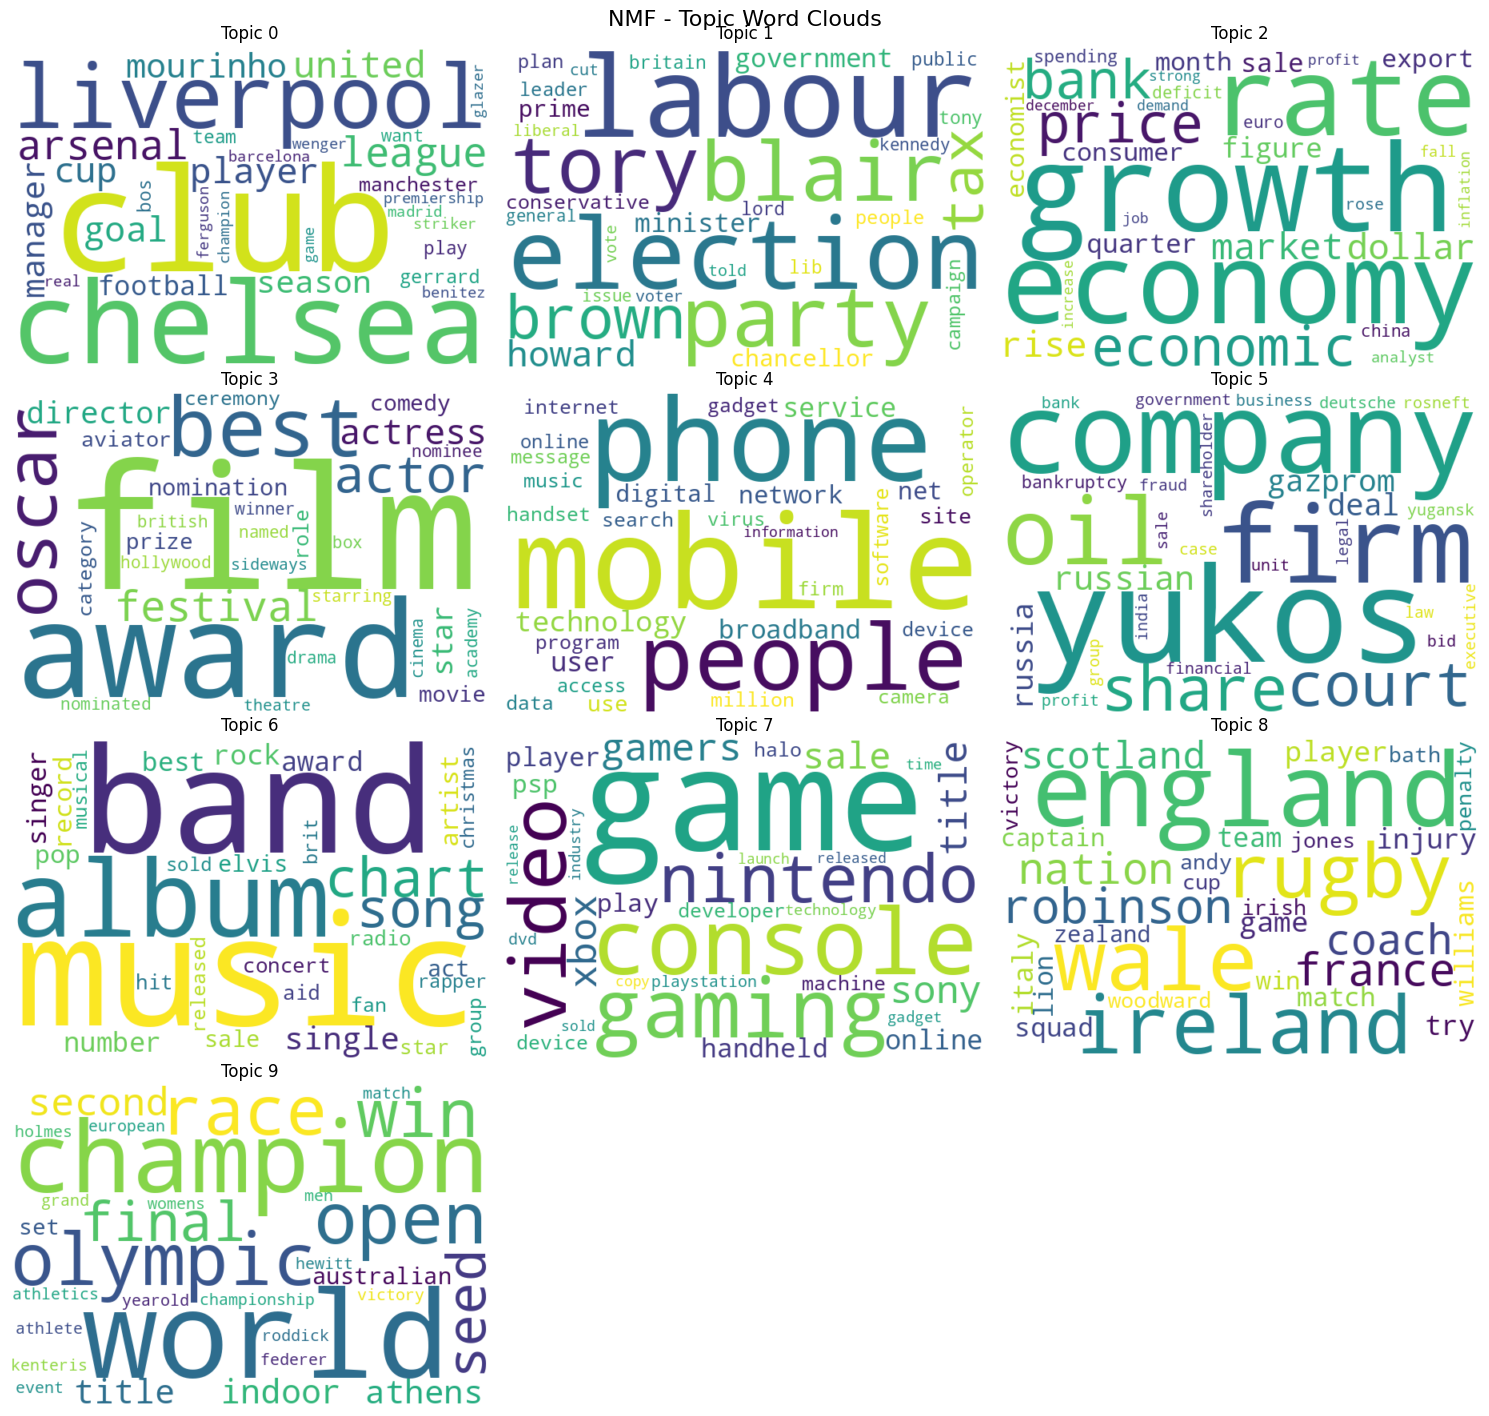

In [14]:
plot_wordclouds(lambda i: nmf_topic_words(i, 30), NUM_TOPICS, "NMF - Topic Word Clouds")

## 9. LDA vs NMF comparison

,Coherence c_v,Coherence u_mass,Topic diversity,Train time (s)
Model,,,,
LDA,0.6328,-1.4920,0.79,23.2126
NMF,0.8033,-1.4119,0.98,1.1454


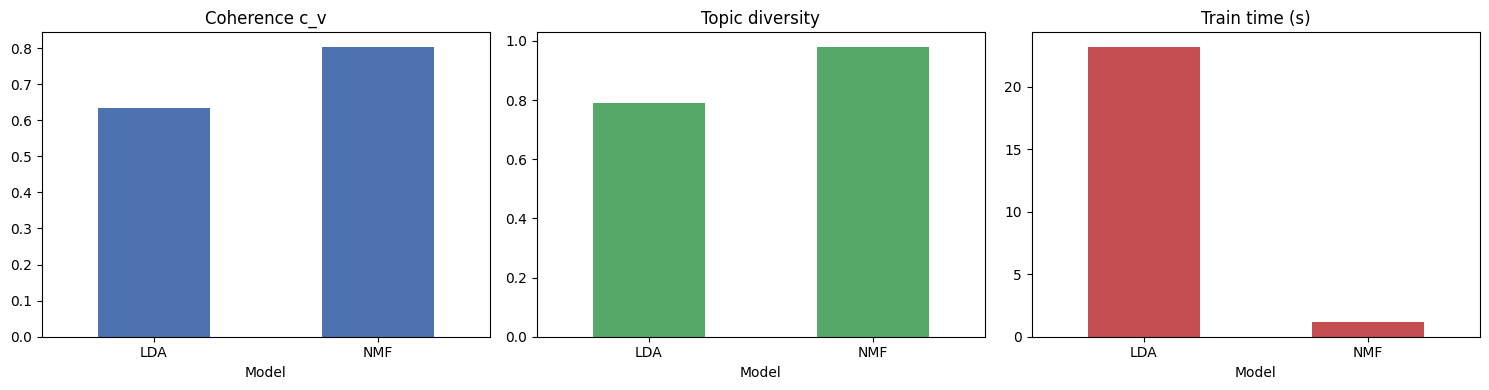

In [15]:
def topics_from_lda(n=10):
    return [[w for w, _ in lda.show_topic(i, topn=n)] for i in range(NUM_TOPICS)]
def topics_from_nmf(n=10):
    return [[w for w, _ in nmf_topic_words(i, n)] for i in range(NUM_TOPICS)]

def coherence(topics, kind="c_v"):
    return CoherenceModel(topics=topics, texts=texts, dictionary=dictionary, coherence=kind).get_coherence()

def topic_diversity(topics):
    words = [w for t in topics for w in t]
    return len(set(words)) / len(words)

lda_topics, nmf_topics = topics_from_lda(), topics_from_nmf()
results = pd.DataFrame({
    "Model": ["LDA", "NMF"],
    "Coherence c_v": [coherence(lda_topics, "c_v"), coherence(nmf_topics, "c_v")],
    "Coherence u_mass": [coherence(lda_topics, "u_mass"), coherence(nmf_topics, "u_mass")],
    "Topic diversity": [topic_diversity(lda_topics), topic_diversity(nmf_topics)],
    "Train time (s)": [lda_time, nmf_time],
}).set_index("Model").round(4)
display(results)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col, color in zip(axes, ["Coherence c_v", "Topic diversity", "Train time (s)"], ["#4c72b0", "#55a868", "#c44e52"]):
    results[col].plot(kind="bar", ax=ax, color=color, rot=0); ax.set_title(col)
plt.tight_layout(); plt.show()

In [16]:
# Side-by-side top words
rows = []
for i in range(NUM_TOPICS):
    rows.append({"Topic": i, "LDA top words": ", ".join(lda_topics[i][:8]), "NMF top words": ", ".join(nmf_topics[i][:8])})
pd.set_option("display.max_colwidth", 120)
pd.DataFrame(rows).set_index("Topic")

,LDA top words,NMF top words
Topic,,
0,"game, people, software, time, apple, program, way, user","club, chelsea, liverpool, arsenal, league, united, player, goal"
1,"labour, party, election, people, tory, government, howard, blair","labour, election, party, blair, tory, brown, tax, howard"
2,"best, award, sale, film, people, million, time, british","growth, economy, rate, economic, price, bank, market, dollar"
3,"game, england, player, win, team, time, club, ireland","film, award, best, oscar, actor, festival, actress, director"
4,"game, technology, open, player, set, gadget, world, search","mobile, phone, people, technology, service, user, broadband, network"
5,"firm, company, phone, mobile, service, people, net, network","yukos, company, firm, oil, share, court, russian, gazprom"
6,"government, market, economy, country, growth, price, economic, tax","music, band, album, chart, song, single, rock, award"
7,"film, award, best, star, actor, director, festival, movie","game, console, gaming, video, nintendo, gamers, xbox, title"
8,"lord, blair, government, minister, court, case, told, right","england, wale, ireland, rugby, robinson, france, nation, coach"


In [17]:
# Agreement between the two models' document assignments (NMI: 1 = identical clustering)
from sklearn.metrics import normalized_mutual_info_score
print("NMI between LDA and NMF assignments:", round(normalized_mutual_info_score(df["lda_topic"], df["nmf_topic"]), 4))

NMI between LDA and NMF assignments: 0.5492
